In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pycaret

import sys
import os



# Cargar archiv
df = pd.read_csv('../data/housing.csv')

display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### 1. tratamiento de valores nulos
Se detectan valores nulos en la columna total_bedrooms, decidimos que en vez de eliminar estos datos se rellenaron con la mediana de la columna para no perder informacion durante el proceso.

In [2]:
# Rellenar los nulos con la mediana
mediana_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(mediana_bedrooms)

### 2. transformacion de continuo a binario
Se transforma la variable objetivo original (median_house_value, que es un valor continuo) a una variable binaria (target_clasification), esta indica si el valor de la casa supera o no el umbral de 240.000 dolares, cambiando el problema de regresion a uno de clasificacion.


In [3]:
# tranformar variables predictia a 1 y 0
df['target_clasificacion'] = (df['median_house_value'] > 240000).astype(int)

### 3. relacion, creacion y eliminacion
gracias al analisis de los datos podemos ver que hay una gran relacion entre las columnas total_rooms, total_bedrooms, population y households, asi que se usaron para crear 3 nuevas columnas a partir de estos (rooms_per_household (cuartos por casa), bedrooms_per_room (proporcion de dormitorios sobre el total de cuartos) y population_per_household (poblacion por casa)) y despues se borraron para evitar que el modelo genere redundancia

In [4]:
#Crear variables
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

#Eliminar
columnas_a_borrar = ['total_rooms', 'total_bedrooms', 'population', "households"]
df = df.drop(columns=columnas_a_borrar)

In [5]:
display(df.head())

,longitude,latitude,housing_median_age,median_income,median_house_value,ocean_proximity,target_clasificacion,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,8.3252,452600.0,NEAR BAY,1,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,8.3014,358500.0,NEAR BAY,1,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,7.2574,352100.0,NEAR BAY,1,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,5.6431,341300.0,NEAR BAY,1,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,3.8462,342200.0,NEAR BAY,1,6.281853,0.172096,2.181467


### 4. influencia y division geografica
para el capturar la influencia de la ubicacion geografica de una forma apropiada que usar las coordenadas se define en src zonas_utils.py una funcion que asigna seis zonas de california (jefferson, north california, silicon valley, west california, south california y central california). se aplica esta funciona dentro del dataframe revisando cuantas viviendas quedaron en cada zona respectivamente.

In [6]:
# Asegurar que Python reconozca la carpeta src para importar módulos
#(ni idea como funciona estos)
sys.path.append(os.path.abspath(os.path.join('..')))
from src.zonas_utils import asignar_zona_california



# 2. Aplicar la función de transformación de zonas
df = asignar_zona_california(df)

# 3. Mostrar un resumen de cuántas viviendas quedaron en cada zona
print("--- Distribución de viviendas por Zona de California ---")
print(df['zona_california'].value_counts())

# Guardar los cambios en el archivo limpio o en uno nuevo
display(df[['longitude', 'latitude', 'zona_california']].head(5))

--- Distribución de viviendas por Zona de California ---
zona_california
West California       7439
Silicon Valley        4450
South California      4246
Central California    2039
North California      1902
Jefferson              564
Name: count, dtype: int64


,longitude,latitude,zona_california
0,-122.23,37.88,Silicon Valley
1,-122.22,37.86,Silicon Valley
2,-122.24,37.85,Silicon Valley
3,-122.25,37.85,Silicon Valley
4,-122.25,37.85,Silicon Valley


In [7]:
df_g=df

In [8]:

plt.figure(figsize=(10, 7))

# Gráfico de dispersión geográfico usando las zonas creadas como matiz (hue)
sns.scatterplot(
    x='longitude',
    y='latitude',
    data=df_g,
    hue='zona_california',
    palette='Set2',
    alpha=0.7,
    s=30
)

plt.title('Mapa de Dispersión Geográfico por Zonas de California', fontsize=14)
plt.xlabel('Longitud (Longitude)', fontsize=12)
plt.ylabel('Latitud (Latitude)', fontsize=12)
plt.legend(title='Zonas de California', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

<Figure size 1000x700 with 1 Axes>

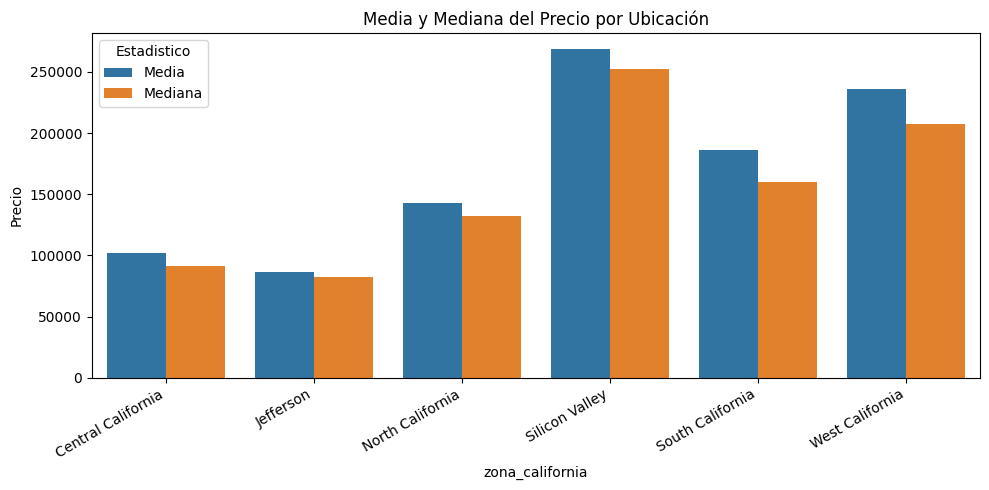

In [9]:
from src.zonas_utils import graficar_media_mediana_ubicacion

# Asegúrate de que 'median_house_value' aún esté en df antes de eliminarlo
graficar_media_mediana_ubicacion(df, col_ubicacion="zona_california")

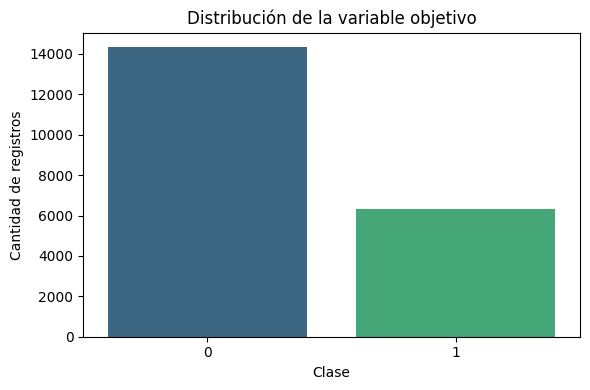

In [10]:
from src.zonas_utils import graficar_conteo_objetivo

graficar_conteo_objetivo(df["target_clasificacion"])

### 5. eliminacion de coordenadas y ingreso medio
tras la creacion de la variable de zona y verificar su relacion con el precio se eliminaron la longitud, latitude y median_house_value, las coordenadas quedaron inutiles por el mapa de zona_california y median_house_value se elimina al ser la variable a partir se construye target_clasification, dejar median_house_value solo produciria data leakage pues "veria" las respuestas directamente en vez de aprender a predecirlas.

In [11]:
columnas_a_borrar = ['longitude', 'latitude',"median_house_value"]
df = df.drop(columns=columnas_a_borrar)

In [12]:
df.head()

,housing_median_age,median_income,ocean_proximity,target_clasificacion,rooms_per_household,bedrooms_per_room,population_per_household,zona_california
0,41.0,8.3252,NEAR BAY,1,6.984127,0.146591,2.555556,Silicon Valley
1,21.0,8.3014,NEAR BAY,1,6.238137,0.155797,2.109842,Silicon Valley
2,52.0,7.2574,NEAR BAY,1,8.288136,0.129516,2.802260,Silicon Valley
3,52.0,5.6431,NEAR BAY,1,5.817352,0.184458,2.547945,Silicon Valley
4,52.0,3.8462,NEAR BAY,1,6.281853,0.172096,2.181467,Silicon Valley


### 6. one-shot encoding
para que los modelos de aprendizaje automatico puedan trabajar con las variables como ocean_proximity y zona_california) se le aplica one-shot encoding, que convierte en columnas binarias, drop_fisrt=true esta para evitar las variables dummy (Las columnas generadas dicen exactamente lo mismo combinadas, así que el modelo se puede confundir), el resultado totalmente numerico se guarda en Housing_limpio.csv para ser usado por el modelo.

In [13]:
# 1. Detectar variables categóricas de texto
columnas_categoricas = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Variables categóricas detectadas para transformar:", columnas_categoricas)

# 2. Aplicar One-Hot Encoding
df = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True)

# 3. Guardar el archivo limpio y completamente numérico (o actualizar housing_limpio.csv)
df.to_csv('../data/housing_limpio.csv', index=False)
print("¡Transformación y codificación completadas con éxito en el archivo limpio!")

Variables categóricas detectadas para transformar: ['ocean_proximity', 'zona_california']
¡Transformación y codificación completadas con éxito en el archivo limpio!


In [14]:
#Guardar nuevo
df.to_csv('../data/housing_limpio.csv', index=False)
print("hola mundo")

hola mundo


## 7. Conclucion:

Con el análisis exploratorio inicial se identifica una correlación alta entre las variables de total_rooms, total_bedrooms, population y households, lo cual permitirá más adelante el construir nuevas variables a partir de estas que aporten más información al modelo sin introducir redundancia.
Adicionalmente, se observa que la distribución de los precios está relacionada con la ubicación geográfica de las viviendas por lo que esta información también resulta valiosa para el modelo predictivo.